2024-10-14 10:47:06.131926: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-14 10:47:06.360939: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-14 10:47:06.418963: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-14 10:47:06.884497: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-14 10:47:12.402481: W ten

Processing 417 images...
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step
Processing 1 images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
Processing 1 images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


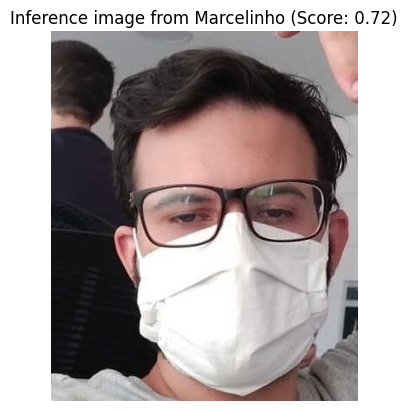

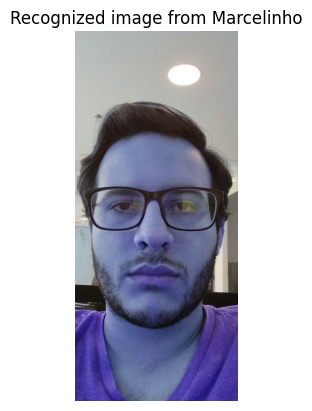

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from keras.models import Model
from keras.applications import MobileNetV2
from keras.preprocessing import image
from sklearn.metrics.pairwise import cosine_similarity
import dlib
from typing import Dict, Tuple, List


class FaceRecognitionConfig:
    IMAGE_SIZE: Tuple[int, int] = (224, 224)


class FaceRecognizer:
    def __init__(self, model: Model, config: FaceRecognitionConfig):
        self.model = model
        self.config = config

    def detect_and_crop_face(self, img_path: str) -> np.ndarray:
        """Detect and crop the face from an image."""
        detector = dlib.get_frontal_face_detector()
        img = cv2.imread(img_path)

        if img is None:
            raise ValueError(f"Unable to load image at {
                             img_path}. Check the file path.")

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = detector(gray)

        if faces:
            face = faces[0]
            x, y, w, h = face.left(), face.top(), face.width(), face.height()
            return img[y:y+h, x:x+w]
        else:
            return img  # Return original image if no face is detected

    def resize_image_with_aspect_ratio(self, img: np.ndarray) -> np.ndarray:
        """Resize image while maintaining the aspect ratio."""
        h, w = img.shape[:2]
        scale = min(self.config.IMAGE_SIZE[1] / w,
                    self.config.IMAGE_SIZE[0] / h)
        new_w, new_h = int(w * scale), int(h * scale)

        resized_img = cv2.resize(
            img, (new_w, new_h), interpolation=cv2.INTER_AREA)
        final_img = np.zeros(
            (self.config.IMAGE_SIZE[0], self.config.IMAGE_SIZE[1], 3), dtype=np.uint8)
        y_offset = (self.config.IMAGE_SIZE[0] - new_h) // 2
        x_offset = (self.config.IMAGE_SIZE[1] - new_w) // 2
        final_img[y_offset:y_offset+new_h,
                  x_offset:x_offset+new_w] = resized_img

        return final_img

    def get_descriptors(self, img_paths: List[str]) -> np.ndarray:
        """Generate descriptors for the provided images."""
        print(f'Processing {len(img_paths)} images...')
        img_list = []

        for img_path in img_paths:
            face_img = self.detect_and_crop_face(img_path)
            resized_img = self.resize_image_with_aspect_ratio(face_img)
            img_array = image.img_to_array(resized_img)
            img_list.append(img_array)

        img_array_batch = np.array(img_list) / 255.0  # Normalize images
        return self.model.predict(img_array_batch)

    def add_new_person(self, database: Dict[str, np.ndarray], new_person_image_path: str, new_person_name: str) -> None:
        """Add a new person to the database."""
        new_descriptor = self.get_descriptors([new_person_image_path])[0]
        database[new_person_name] = new_descriptor

    def recognize_person(self, database: Dict[str, np.ndarray], mask_image_path: str) -> Tuple[str, float]:
        """Recognize a person from a masked image."""
        masked_descriptor = self.get_descriptors([mask_image_path])[0]

        scores = {name: cosine_similarity(masked_descriptor.reshape(1, -1), descriptor.reshape(1, -1))[0][0]
                  for name, descriptor in database.items()}

        recognized_person = max(scores, key=scores.get)
        recognized_score = scores[recognized_person]

        return recognized_person, recognized_score

    def display_recognition_result(self, mask_image_path: str, recognized_person: str, recognized_score: float) -> None:
        """Display the recognition result."""
        img = cv2.cvtColor(cv2.imread(mask_image_path), cv2.COLOR_BGR2RGB)
        plt.imshow(img)
        title = f'Inference image from {recognized_person} (Score: {
            recognized_score:.2f})' if recognized_person else 'Recognition failed.'
        plt.title(title)
        plt.axis('off')
        plt.figure()
        if recognized_person == 'Marcelinho':
            plt.imshow(cv2.imread('./marcelinho_no_db.jpg'))
        else:
            plt.imshow(cv2.imread('./test/' + recognized_person +
                       '/' + os.listdir('./test/' + recognized_person)[0]))
        plt.title(f'Recognized image from {recognized_person}')
        plt.axis('off')
        plt.show()


def create_database(image_directory: str, recognizer: FaceRecognizer) -> Dict[str, np.ndarray]:
    """Create a database of facial descriptors."""
    database = {}
    img_paths = []

    for celeb_name in os.listdir(image_directory):
        celeb_dir = os.path.join(image_directory, celeb_name)
        for celeb_photo in os.listdir(celeb_dir):
            celeb_photo_path = os.path.join(celeb_dir, celeb_photo)
            img_paths.append(celeb_photo_path)

    descriptors = recognizer.get_descriptors(img_paths)

    # Add descriptors to the database
    for i, celeb_name in enumerate(os.listdir(image_directory)):
        database[celeb_name] = descriptors[i]

    return database


def main() -> None:
    """Main function to run the face recognition pipeline."""
    image_directory = './test'
    config = FaceRecognitionConfig()
    # Load MobileNetV2 model with imagenet that has been pre-trained on ImageNet
    model = MobileNetV2(weights='imagenet', include_top=False,
                        pooling='avg', input_shape=(224, 224, 3))
    recognizer = FaceRecognizer(model, config)

    database = create_database(image_directory, recognizer)

    new_person_image_path = './marcelinho_no_db.jpg'
    new_person_name = 'Marcelinho'
    recognizer.add_new_person(database, new_person_image_path, new_person_name)

    mask_image_path = './marcelinho_na_inferencia.jpg'
    recognized_person, recognized_score = recognizer.recognize_person(
        database, mask_image_path)

    recognizer.display_recognition_result(
        mask_image_path, recognized_person, recognized_score)


if __name__ == '__main__':
    main()
